In [2]:
import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

In [3]:
from skbio.stats.composition import clr, clr_inv, ilr, ilr_inv
from jax.scipy.optimize import minimize as jmin
from scipy.optimize import minimize, least_squares
from scipy import stats
import optimistix

In [4]:
from emu_example import simple_net, clr_func, clr_inv_func, aitchison, objective_wssr, objective_clr_wssr, calc_ci

In [5]:
solver = optimistix.BFGS(
    rtol=1e-12, atol=1e-12, verbose=frozenset({"step"})
)

In [85]:
# Defining the true fluxes 
M = jnp.array([[-1,-1,2], 
               [0,0,-1], 
               [-1,0,1]])
v1 = 25
v3 = 100
v5 = 22
v_free = jnp.array([v1,v3,v5]) 
v2, v4, v6 = -M @ v_free

v_true = jnp.array([v1,v2,v3,v4,v5,v6])

# Defining an array with the free fluxes. 
params = jnp.array([v3, v5], dtype=float)
n_params = len(params)

# Define the true MID for the example- 
data = simple_net(params, v1=v1)
print(data)
# print(f"v1= ", v1, "v3= ", v3, "data= ", data)

[0.01807152 0.60881514 0.33388992 0.03922342]


In [86]:
# v1_range = np.linspace(25, 50, 10)
# v3_range = np.linspace(75, 100, 10)

# v1_grid, v3_grid = np.meshgrid(v1_range, v3_range)

# for i in range(10):
#     for j in range(10):
#         v1 = v1_grid[i,j]
#         v3 = v3_grid[i,j]
#         v_free = jnp.array([v1,v3,v5]) 
#         v2, v4, v6 = -M @ v_free
#         params = jnp.array([v3, v5], dtype=float)
#         data = simple_net(params, v1=v1)
#         print(f"v1= ", v1, "v3= ", v3, "data= ", data)


# Data simulation

In [118]:
# Making simulated data. 
total_mol = 1e5
total_isos = total_mol*data
rng = np.random.default_rng(seed=1234)

sims = 1000
# norm_sigma = total_mol*0.0002
# norm_sigma = total_isos*0.015
norm_sigma = np.array([total_isos[0]*0.3, total_isos[1]*0.05, total_isos[2]*0.05, total_isos[3]*0.3])
norm_sim = np.array(total_isos + rng.normal(0, norm_sigma, size=(sims,4)))
# np.clip(norm_sim, 1e-12, None, out=norm_sim)

# lognorm_sim = np.exp(np.log(total_isos) + rng.normal(0, 0.07, size=(sims, 4)))
df = pl.from_numpy(norm_sim, schema=["m0", "m1", "m2", "m3"])
df.insert_column(column=(pl.col("m0")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m0_com"), index=4)
df.insert_column(column=(pl.col("m1")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m1_com"), index=5)
df.insert_column(column=(pl.col("m2")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m2_com"), index=6)
df.insert_column(column=(pl.col("m3")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m3_com"), index=7)

m0,m1,m2,m3,m0_com,m1_com,m2_com,m3_com
f64,f64,f64,f64,f64,f64,f64,f64
937.639023,61076.638996,34625.872854,4101.929036,0.009307,0.606267,0.343708,0.040717
2275.427169,69749.208561,30920.17109,5034.882059,0.021073,0.645947,0.286352,0.046628
903.86408,61927.898532,32533.493221,5480.012118,0.008963,0.614088,0.322608,0.054341
1340.755007,62462.890628,31276.898487,1381.677389,0.013899,0.647537,0.32424,0.014324
2042.841295,66157.777905,34257.329934,2743.09066,0.019418,0.62887,0.325637,0.026075
…,…,…,…,…,…,…,…
1896.656859,58919.980307,31998.451644,3213.158202,0.019751,0.613569,0.333219,0.033461
1575.208124,59891.452388,31175.225475,4378.260208,0.016236,0.617309,0.321327,0.045127
1979.495498,60168.913645,33582.820309,4367.250426,0.019775,0.601097,0.335498,0.04363


In [119]:
D_sim_vec = jnp.array([statistics.stdev(df["m0_com"]), statistics.stdev(df["m1_com"]), statistics.stdev(df["m2_com"]), statistics.stdev(df["m3_com"])])
D_sim_vec

Array([0.00538443, 0.01789672, 0.01573868, 0.01133088], dtype=float64)

In [120]:
f123_sim = jnp.array([statistics.mean(df["m0_com"]), statistics.mean(df["m1_com"]), statistics.mean(df["m2_com"]), statistics.mean(df["m3_com"])])
D_sim = jnp.diag(D_sim_vec)

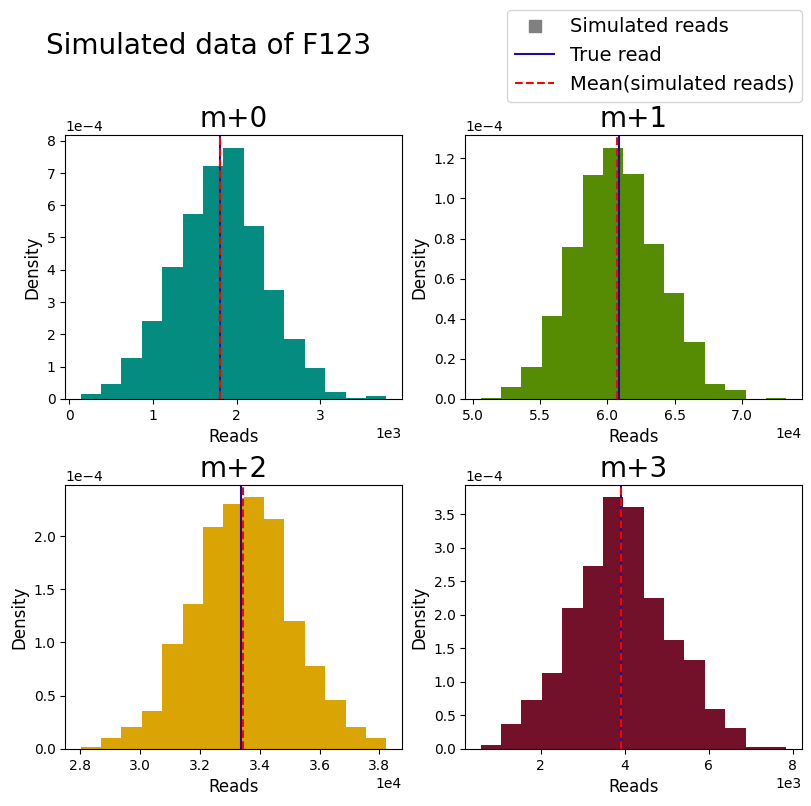

In [121]:
colors =["#73102A", "#038C7F", "#558C03", "#F2CB05", "#D9A404", "#1C0B9C"]

fig, ((ax1, ax2),(ax3,ax4)) = plt.subplots(nrows=2, ncols=2, figsize=(8,8), layout="constrained")
ax1.hist(df["m0"].to_numpy(), bins=15, density=True, label="Simulated m+0", color=colors[1])
ax2.hist(df["m1"].to_numpy(), bins=15, density=True, label="Simulated m+1", color=colors[2])
ax3.hist(df["m2"].to_numpy(), bins=15, density=True, label="Simulated m+2", color=colors[4])
ax4.hist(df["m3"].to_numpy(), bins=15, density=True, label="Simulated m+3", color=colors[0])

ax1.axvline(total_isos[0], color=colors[5], label="True")
ax2.axvline(total_isos[1], color=colors[5], label="True")
ax3.axvline(total_isos[2], color=colors[5], label="True")
ax4.axvline(total_isos[3], color=colors[5], label="True")

total_mean = jnp.array([statistics.mean(df["m0"]), statistics.mean(df["m1"]), statistics.mean(df["m2"]), statistics.mean(df["m3"])])

ax1.axvline(total_mean[0], color="red", linestyle="dashed", label="Mean")
ax2.axvline(total_mean[1], color="red", linestyle="dashed", label="Mean")
ax3.axvline(total_mean[2], color="red", linestyle="dashed", label="Mean")
ax4.axvline(total_mean[3], color="red", linestyle="dashed", label="Mean")


ax1.set_title("m+0", size=20)
ax2.set_title("m+1", size=20)
ax3.set_title("m+2", size=20)
ax4.set_title("m+3", size=20)

ax1.set_xlabel("Reads", size=12)
ax2.set_xlabel("Reads", size=12)
ax3.set_xlabel("Reads", size=12)
ax4.set_xlabel("Reads", size=12)

ax1.set_ylabel("Density", size=12)
ax2.set_ylabel("Density", size=12)
ax3.set_ylabel("Density", size=12)
ax4.set_ylabel("Density", size=12)

ax1.ticklabel_format(scilimits=(-2,2))
ax2.ticklabel_format(scilimits=(-2,2))
ax3.ticklabel_format(scilimits=(-2,2))
ax4.ticklabel_format(scilimits=(-2,2))

# Custom legend
custom_marker = [
    Line2D([0], [0], color="gray", marker="s", linestyle="", markersize=8),
    Line2D([0], [0], color=colors[5], marker="", linestyle="-", markersize=8),
    Line2D([0], [0], color="red", marker="", linestyle="dashed", markersize=8)
]
fig.legend(custom_marker, ["Simulated reads", "True read", "Mean(simulated reads)"], fontsize=14, loc="outside upper right")

fig.suptitle("Simulated data of F123", size=20, x=0.05, y=0.96, ha="left")

plt.show()

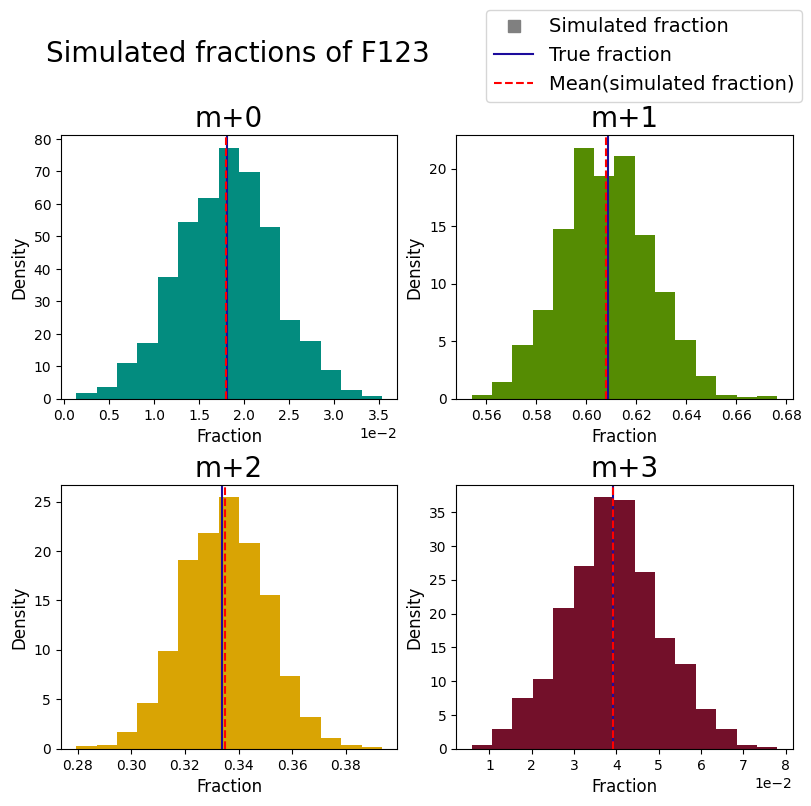

In [122]:
fig, ((ax1, ax2),(ax3,ax4)) = plt.subplots(nrows=2, ncols=2, figsize=(8,8), layout="constrained")
ax1.hist(df["m0_com"].to_numpy(), bins=15, density=True, label="Simulated m0", color=colors[1])
ax2.hist(df["m1_com"].to_numpy(), bins=15, density=True, label="Simulated m1", color=colors[2])
ax3.hist(df["m2_com"].to_numpy(), bins=15, density=True, label="Simulated m2", color=colors[4])
ax4.hist(df["m3_com"].to_numpy(), bins=15, density=True, label="Simulated m3", color=colors[0])

ax1.axvline(data[0], color=colors[5], label="True")
ax2.axvline(data[1], color=colors[5], label="True")
ax3.axvline(data[2], color=colors[5], label="True")
ax4.axvline(data[3], color=colors[5], label="True")

ax1.axvline(f123_sim[0], color="red", linestyle="dashed", label="Mean")
ax2.axvline(f123_sim[1], color="red", linestyle="dashed", label="Mean")
ax3.axvline(f123_sim[2], color="red", linestyle="dashed", label="Mean")
ax4.axvline(f123_sim[3], color="red", linestyle="dashed", label="Mean")

ax1.set_title("m+0", size=20)
ax2.set_title("m+1", size=20)
ax3.set_title("m+2", size=20)
ax4.set_title("m+3", size=20)

ax1.set_xlabel("Fraction", size=12)
ax2.set_xlabel("Fraction", size=12)
ax3.set_xlabel("Fraction", size=12)
ax4.set_xlabel("Fraction", size=12)

ax1.set_ylabel("Density", size=12)
ax2.set_ylabel("Density", size=12)
ax3.set_ylabel("Density", size=12)
ax4.set_ylabel("Density", size=12)

ax1.ticklabel_format(scilimits=(-2,2))
ax2.ticklabel_format(scilimits=(-2,2))
ax3.ticklabel_format(scilimits=(-2,2))
ax4.ticklabel_format(scilimits=(-2,2))

# Custom legend
custom_marker = [
    Line2D([0], [0], color="gray", marker="s", linestyle="", markersize=8),
    Line2D([0], [0], color=colors[5], marker="", linestyle="-", markersize=8),
    Line2D([0], [0], color="red", marker="", linestyle="dashed", markersize=8)
]
fig.legend(custom_marker, ["Simulated fraction", "True fraction", "Mean(simulated fraction)"], fontsize=14, loc="outside upper right")

fig.suptitle("Simulated fractions of F123", size=20, x=0.05, y=0.95, ha = "left")

# plt.legend(loc="upper right")

plt.show()

## CLR transformed simulations

In [126]:
rng = np.random.default_rng(seed=1234)
clr_data = clr(data)
sims = 1000
norm_clr = np.array(clr_data+ rng.normal(0, 0.001, size=(sims,4)))


In [127]:
clr_arr = clr(pl.DataFrame(data= {"m0": df["m0_com"], "m1": df["m1_com"], "m2": df["m2_com"], "m3": df["m3_com"]}))
clr_m0 = np.array([clr_arr[i][0] for i in range(len(clr_arr))])
clr_m1 = np.array([clr_arr[i][1] for i in range(len(clr_arr))])
clr_m2 = np.array([clr_arr[i][2] for i in range(len(clr_arr))])
clr_m3 = np.array([clr_arr[i][3] for i in range(len(clr_arr))])

df_clr = pl.DataFrame(
    data={
        "m0": df["m0_com"], 
        "m1": df["m1_com"],
        "m2": df["m2_com"],
        "m3": df["m3_com"],
        "m0_clr": clr_m0,
        "m1_clr": clr_m1,
        "m2_clr": clr_m2,
        "m3_clr": clr_m3,
    }
)
df_clr

m0,m1,m2,m3,m0_clr,m1_clr,m2_clr,m3_clr
f64,f64,f64,f64,f64,f64,f64,f64
0.009307,0.606267,0.343708,0.040717,-2.31534,1.86118,1.293652,-0.839492
0.021073,0.645947,0.286352,0.046628,-1.70655,1.716188,0.902691,-0.912328
0.008963,0.614088,0.322608,0.054341,-2.403144,1.823903,1.180202,-0.600961
0.013899,0.647537,0.32424,0.014324,-1.755263,2.086077,1.394384,-1.725198
0.019418,0.62887,0.325637,0.026075,-1.648001,1.8297,1.171558,-1.353257
…,…,…,…,…,…,…,…
0.019751,0.613569,0.333219,0.033461,-1.697211,1.738877,1.128384,-1.170049
0.016236,0.617309,0.321327,0.045127,-1.911412,1.726735,1.073825,-0.889148
0.019775,0.601097,0.335498,0.04363,-1.759195,1.655119,1.071978,-0.967903


In [128]:
f123_sim_clr = jnp.array([statistics.mean(df_clr["m0_clr"]), statistics.mean(df_clr["m1_clr"]), statistics.mean(df_clr["m2_clr"]), statistics.mean(df_clr["m3_clr"])])

D_sim_clr = jnp.diag(jnp.array([statistics.stdev(df_clr["m0_clr"]), statistics.stdev(df_clr["m1_clr"]), statistics.stdev(df_clr["m2_clr"]), statistics.stdev(df_clr["m3_clr"])]))

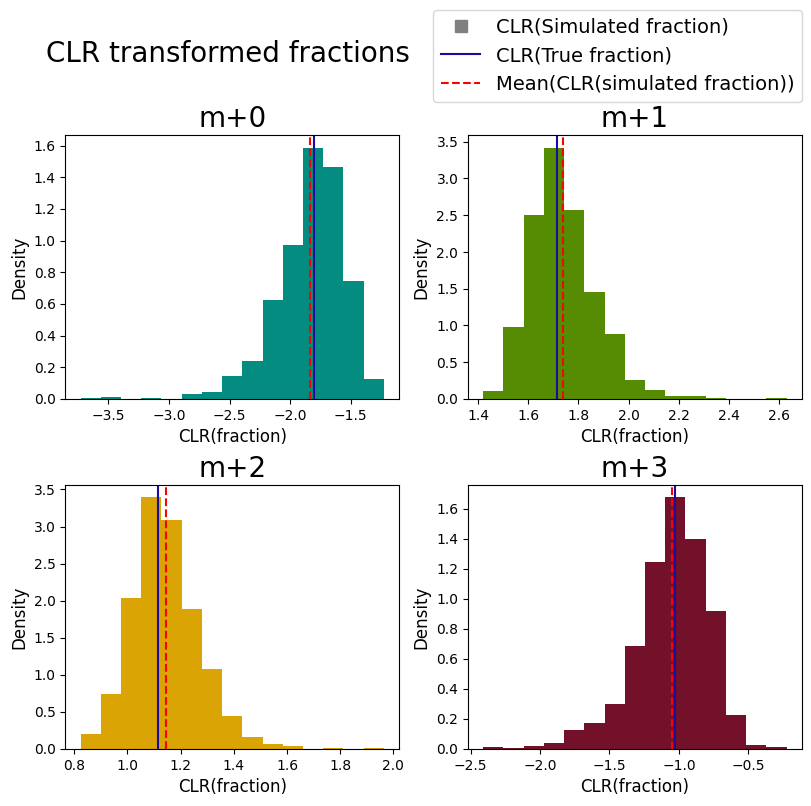

In [129]:
fig_clr, ((ax1_clr, ax2_clr),(ax3_clr,ax4_clr)) = plt.subplots(nrows=2, ncols=2, figsize=(8,8), layout="constrained")
ax1_clr.hist(df_clr["m0_clr"].to_numpy(), bins=15, density=True, label="Simulated m0", color=colors[1])
ax2_clr.hist(df_clr["m1_clr"].to_numpy(), bins=15, density=True, label="Simulated m1", color=colors[2])
ax3_clr.hist(df_clr["m2_clr"].to_numpy(), bins=15, density=True, label="Simulated m2", color=colors[4])
ax4_clr.hist(df_clr["m3_clr"].to_numpy(), bins=15, density=True, label="Simulated m3", color=colors[0])

data_clr=clr_func(data)
ax1_clr.axvline(data_clr[0], color=colors[5], label="True")
ax2_clr.axvline(data_clr[1], color=colors[5], label="True")
ax3_clr.axvline(data_clr[2], color=colors[5], label="True")
ax4_clr.axvline(data_clr[3], color=colors[5], label="True")

ax1_clr.axvline(f123_sim_clr[0], color="red", linestyle="dashed", label="Mean")
ax2_clr.axvline(f123_sim_clr[1], color="red", linestyle="dashed", label="Mean")
ax3_clr.axvline(f123_sim_clr[2], color="red", linestyle="dashed", label="Mean")
ax4_clr.axvline(f123_sim_clr[3], color="red", linestyle="dashed", label="Mean")

ax1_clr.set_title("m+0", size=20)
ax2_clr.set_title("m+1", size=20)
ax3_clr.set_title("m+2", size=20)
ax4_clr.set_title("m+3", size=20)

ax1_clr.set_xlabel("CLR(fraction)", size=12)
ax2_clr.set_xlabel("CLR(fraction)", size=12)
ax3_clr.set_xlabel("CLR(fraction)", size=12)
ax4_clr.set_xlabel("CLR(fraction)", size=12)

ax1_clr.set_ylabel("Density", size=12)
ax2_clr.set_ylabel("Density", size=12)
ax3_clr.set_ylabel("Density", size=12)
ax4_clr.set_ylabel("Density", size=12)

# Custom legend
custom_marker = [
    Line2D([0], [0], color="gray", marker="s", linestyle="", markersize=8),
    Line2D([0], [0], color=colors[5], marker="", linestyle="-", markersize=8),
    Line2D([0], [0], color="red", marker="", linestyle="dashed", markersize=8)
]
fig_clr.legend(custom_marker, ["CLR(Simulated fraction)", "CLR(True fraction)", "Mean(CLR(simulated fraction))"], fontsize=14, loc="outside upper right")

fig_clr.suptitle("CLR transformed fractions", size=20, x=0.05, y=0.95, ha = "left") 

plt.show()

# Estimation of flux with simulated data

## Euclidean space

In [130]:
# Defining initial guess
initial_guess = jnp.array([100,50])

result_euclidian = optimistix.minimise(objective_wssr, y0=initial_guess, args=(f123_sim, D_sim, v1), solver=solver, max_steps=10000, throw=False)

v3_est, v5_est = result_euclidian.value
print(v3_est, v5_est)

97.67893175112057 21.919017716340182


In [131]:
v_free_est = np.array([v1,v3_est,v5_est])
v2_est, v4_est, v6_est = jnp.dot(-M, v_free_est)
v_est = np.array([v1,v2_est,v3_est,v4_est,v5_est,v6_est])

In [21]:
sensitivity_f123 = jax.jacobian(simple_net, argnums=0)(result_euclidian.value, v1)

Confidence interval based on every single simulation

In [135]:
sims_all = jnp.array([df["m0_com"], df["m1_com"], df["m2_com"], df["m3_com"]])
v_vec = np.zeros((sims, 6)) 
for sim in range(sims):
    data_sim = jnp.array([sims_all[0][sim], sims_all[1][sim], sims_all[2][sim], sims_all[3][sim]])
    result = optimistix.minimise(objective_wssr, y0=initial_guess, args=(data_sim, D_sim, v1), solver=solver, max_steps=100000, throw=False)
    v2_est, v4_est, v6_est = jnp.dot(-M, np.array([v1,result.value[0],result.value[1]]))
    v_vec[sim,:] = np.array([v1,v2_est,result.value[0],v4_est,result.value[1],v6_est])

cis = np.quantile(v_vec, np.array([0.025, 0.975]), axis=0)

In [136]:
v3_CI = jnp.array(cis[:,2])
v5_CI = jnp.array(cis[:,4])
print(f"v3 95% CI: ", v3_CI)
print(f"v3 95% CI: ", v5_CI)

v3 95% CI:  [ 48.32307025 315.13683467]
v3 95% CI:  [15.66552978 29.70100508]


In [ ]:
# # Create a regular grid for smoother contours
# v3_grid = np.linspace(30, 60, 100)
# v5_grid = np.linspace(10, 30, 100)
# V3, V5 = np.meshgrid(v3_grid, v5_grid)
# optimal_value = objective_wssr(result_euclidian.value, args=(f123_sim, D_sim, v1))

# # Compute likelihood on the grid
# lik_mat = np.zeros_like(V3)
# for i in range(V3.shape[0]):
#     for j in range(V3.shape[1]):
#         lik_mat[i, j] = objective_wssr(params=np.array([V3[i, j], V5[i, j]]), args=(f123_sim, D_sim, v1))-optimal_value

# fig, ax = plt.subplots(figsize=(6, 5))

# # Use contourf with the grid data
# Lmax = lik_mat.max()
# levels = np.linspace(lik_mat.min(), Lmax, 50)

# cf = ax.contourf(V3, V5, lik_mat, levels=levels, cmap='viridis')
# ax.contour(V3, V5, lik_mat, levels=levels, colors='white', linewidths=0.5, alpha=0.5)

# # Mark true parameter values
# ax.axhline(v5, color='red', linestyle='--', linewidth=1.5, label=f'True v5 = {v5}')
# ax.axvline(v3, color='red', linestyle='--', linewidth=1.5, label=f'True v3 = {v3}')
# ax.plot(v3, v5, 'r*', markersize=15, label='True parameters')

# # Mark estimated values
# ax.plot(v3_est, v5_est, 'wo', markersize=10, markeredgecolor='black', markeredgewidth=2, label='Estimated (linear)')

# ax.set_xlabel("v3", fontsize=12)
# ax.set_ylabel("v5", fontsize=12)
# ax.set_title("Log-likelihood surface (linear)", fontsize=14)

# # Add colorbar
# cbar = plt.colorbar(cf, ax=ax)
# cbar.set_label('Log-likelihood', fontsize=11)

# ax.legend(loc='upper right', fontsize=9)
# plt.tight_layout()
# plt.show()

# CLR transformed

In [132]:
# Run optimization
result_clr = optimistix.minimise(objective_clr_wssr, y0=initial_guess, args=(f123_sim_clr, D_sim_clr, v1), solver=solver)
v3_clr, v5_clr = result_clr.value

In [137]:
sims_all_clr = jnp.array([df_clr["m0_clr"], df_clr["m1_clr"], df_clr["m2_clr"], df_clr["m3_clr"]])
v_vec_clr = np.zeros((sims, 6)) 
for sim in range(sims):
    data_sim = jnp.array([sims_all_clr[0][sim], sims_all_clr[1][sim], sims_all_clr[2][sim], sims_all_clr[3][sim]])
    result = optimistix.minimise(objective_clr_wssr, y0=initial_guess, args=(data_sim, D_sim_clr, v1), solver=solver, max_steps=100000, throw=False)
    v2_est, v4_est, v6_est = jnp.dot(-M, np.array([v1,result.value[0],result.value[1]]))
    v_vec_clr[sim,:] = np.array([v1,v2_est,result.value[0],v4_est,result.value[1],v6_est])

In [138]:
cis_clr = np.quantile(v_vec_clr, np.array([0.025, 0.975]), axis=0)

In [139]:
v3_CI_clr = jnp.array(cis_clr[:,2])
v5_CI_clr = jnp.array(cis_clr[:,4])
print(f"CLR v3 95% CI: ", v3_CI_clr)
print(f"CLR v5 95% CI: ", v5_CI_clr)

CLR v3 95% CI:  [ 43.35781258 350.39511333]
CLR v5 95% CI:  [15.92516715 29.57415307]


In [28]:
def run_profile_likelihood(flux_index, start_params, objective_fun, phi_optimal, data, D, v1, direction=1, k_steps=50, step_size=1):
    path = []
    chi2_threshold = 3.84
    
    current_fixed_val = float(start_params[flux_index])
    other_idx = 1 - flux_index
    current_other_guess = jnp.array([start_params[other_idx]])
    
    # Track the MLE point itself
    path.append((current_fixed_val, float(phi_optimal)))

    for k in range(k_steps):
        current_fixed_val += direction * step_size
        if current_fixed_val <= 0:
            break   
        
        # We pass only the parameter to optimize to the solver
        def inner_objective(other_params, args):
            val, d, mat_D, vec_v1 = args
            p = jnp.zeros((2,))
            p = p.at[flux_index].set(val)
            p = p.at[other_idx].set(other_params[0])
            return objective_fun(p, (d, mat_D, vec_v1))

        inner_sol = optimistix.minimise(
            inner_objective,
            solver=optimistix.LevenbergMarquardt(rtol=1e-12, atol=1e-12),
            y0=current_other_guess,
            args=(current_fixed_val, data, D, v1),
            max_steps=10000,
            throw=False
        )
        
        current_other_guess = inner_sol.value
        
        # Reconstruct full vector to calculate final Phi
        p_final = jnp.zeros((2,))
        p_final = p_final.at[flux_index].set(current_fixed_val)
        p_final = p_final.at[other_idx].set(current_other_guess[0])

        phi_u = objective_fun(p_final, (data, D, v1))
        delta_phi = phi_u - phi_optimal
        path.append((float(current_fixed_val), float(phi_u)))

        if delta_phi > chi2_threshold:
            break
        
            
    return path

def add_profile_to_ax(ax, flux_vals, phi_vals, phi_optimal, mle_val, flux_label):
    ax.plot(flux_vals, phi_vals, 'o-', color='teal', markersize=3, label='Profile')
    ax.axvline(mle_val, color='red', linestyle='--', alpha=0.5, label='MLE')
    
    # threshold_val = phi_optimal + 3.84
    # ax.axhline(threshold_val, color='orange', linestyle=':', label=r'95% CI Thresh')
    
    ax.set_title(f"Profile: {flux_label}")
    ax.set_xlabel(f"Value")
    ax.set_ylabel(r"$\Phi(u)$")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize='small')

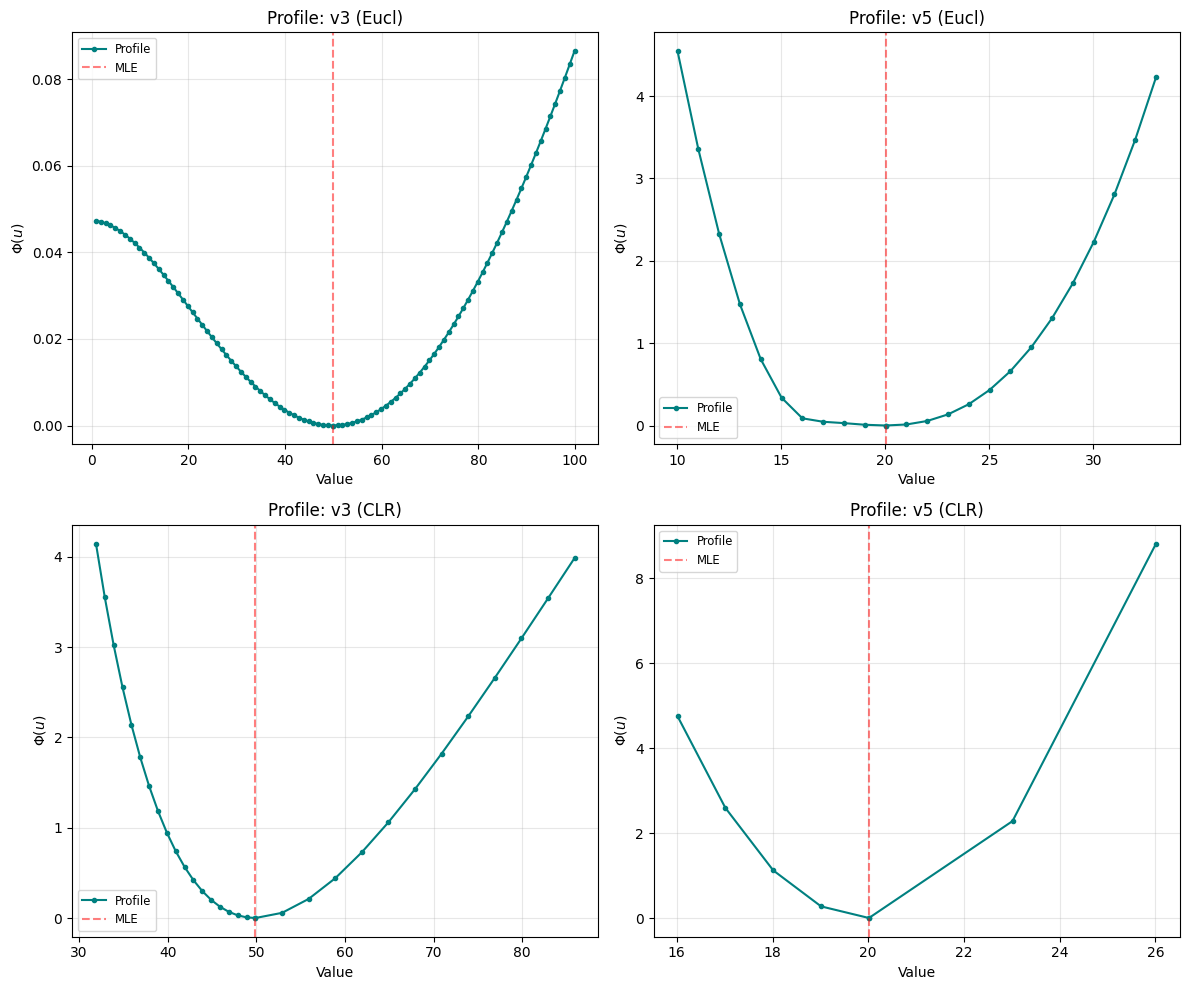

In [29]:
# Setup Figure
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Makes indexing easier: 0, 1, 2, 3

flux_labels = ["v3", "v5"]
phi_optimal = objective_wssr(result_euclidian.value, args=(f123_sim, D_sim, v1))
phi_optimal_clr = objective_clr_wssr(result_clr.value, args=(f123_sim_clr, D_sim_clr, v1))

for i in range(2):
    # --- EUCLIDEAN SECTION ---
    up = run_profile_likelihood(i, result_euclidian.value, objective_wssr, phi_optimal, f123_sim, D_sim, v1, direction=1,)
    down = run_profile_likelihood(i, result_euclidian.value, objective_wssr, phi_optimal, f123_sim, D_sim, v1, direction=-1)
    
    # Combine, sort by flux value, and remove duplicates
    full = sorted(up + down, key=lambda x: x[0])
    flux_v, phi_v = zip(*full)
    
    add_profile_to_ax(axes[i], flux_v, phi_v, phi_optimal, result_euclidian.value[i], f"{flux_labels[i]} (Eucl)")

    # --- CLR SECTION ---
    up_c = run_profile_likelihood(i, result_clr.value, objective_clr_wssr, phi_optimal_clr, f123_sim_clr, D_sim_clr, v1, direction=1, step_size=3)
    down_c = run_profile_likelihood(i, result_clr.value, objective_clr_wssr, phi_optimal_clr, f123_sim_clr, D_sim_clr, v1, direction=-1)
    
    full_c = sorted(up_c + down_c, key=lambda x: x[0])
    flux_vc, phi_vc = zip(*full_c)
    
    add_profile_to_ax(axes[i+2], flux_vc, phi_vc, phi_optimal_clr, result_clr.value[i], f"{flux_labels[i]} (CLR)")

plt.tight_layout()
plt.show()

In [134]:
v_free_clr = np.array([v1,v3_clr,v5_clr])
v2_clr, v4_clr, v6_clr = jnp.dot(-M, v_free_clr)
v_clr = np.array([v1,v2_clr,v3_clr,v4_clr,v5_clr,v6_clr])
print("true flux", v_true)
print("Etimated linear", v_est)
print("Estimated compositional", v_clr)

true flux [ 25  81 100  22  22   3]
Etimated linear [25.         78.84089632 97.67893175 21.91901772 21.91901772  3.08098228]
Estimated compositional [25.         74.86556544 92.32180009 21.22811733 21.22811733  3.77188267]


In [133]:
print("Simulated data: \n", np.round(f123_sim,4), "\n")
print("True data: \n", np.round(data,4), "\n")
print("Linear: \n", np.round(simple_net(parameters=np.array([v3_est, v5_est]), v1=v1),4), "\n")
print("Compositional: \n", np.round(simple_net(parameters=np.array([v3_clr, v5_clr]), v1=v1),4), "\n")

Simulated data: 
 [0.018  0.6078 0.335  0.0391] 

True data: 
 [0.0181 0.6088 0.3339 0.0392] 

Linear: 
 [0.018  0.6078 0.335  0.0392] 

Compositional: 
 [0.017  0.6099 0.3352 0.0379] 



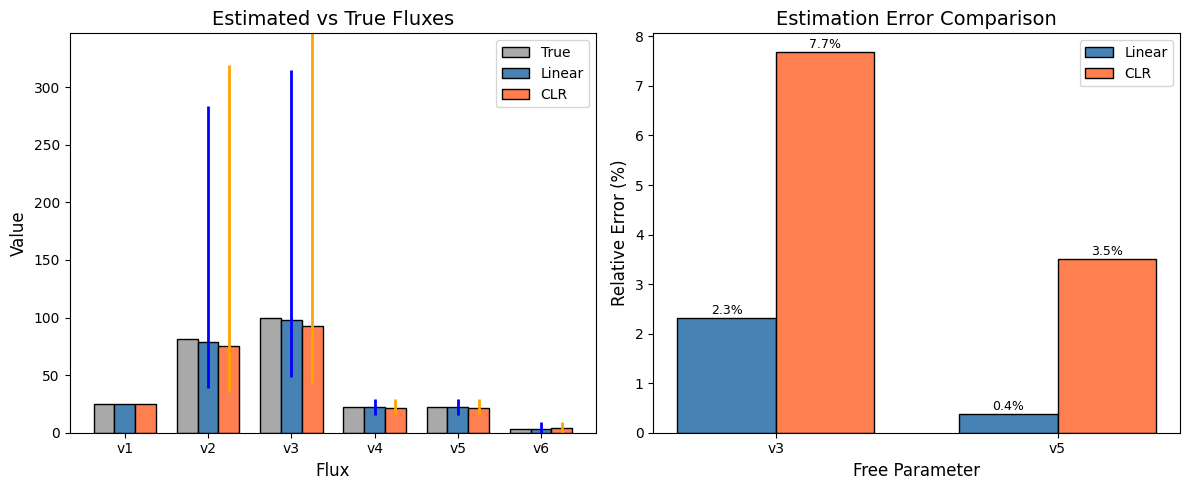

In [140]:
lower_eucli = abs(cis[0,:]-v_est)
upper_eucli = abs(cis[1,:]-v_est)
lower_clr = abs(cis_clr[0,:]-v_clr)
upper_clr = abs(cis_clr[1,:]-v_clr)

# Comparison plot: Estimated fluxes vs True fluxes
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: Bar chart comparing all fluxes
flux_labels = ['v1', 'v2', 'v3', 'v4', 'v5', 'v6']
x = np.arange(len(flux_labels))
width = 0.25
bars1 = axes[0].bar(x - width, v_true, width, label='True', color='darkgray', edgecolor='black')
bars2 = axes[0].bar(x, v_est, width, label='Linear', color='steelblue', edgecolor='black', yerr=[lower_eucli, upper_eucli],error_kw={'elinewidth': 2,'ecolor': "blue"})
bars3 = axes[0].bar(x + width, v_clr, width, label='CLR', color='coral', edgecolor='black', yerr=[lower_clr, upper_clr],error_kw={'elinewidth': 2,'ecolor': 'orange'})

axes[0].set_xlabel('Flux', fontsize=12)
axes[0].set_ylabel('Value', fontsize=12)
axes[0].set_title('Estimated vs True Fluxes', fontsize=14)
axes[0].set_xticks(x)
axes[0].set_xticklabels(flux_labels)
axes[0].legend(fontsize=10)
axes[0].set_ylim(0, max(cis[1,:])*1.1)

# Right: Relative error (%) for free parameters only
free_params = ['v3', 'v5']
true_vals = np.array([v3, v5])
linear_vals = np.array([v3_est, v5_est])
clr_vals = np.array([v3_clr, v5_clr])

rel_error_linear = 100 * np.abs(linear_vals - true_vals) / true_vals
rel_error_clr = 100 * np.abs(clr_vals - true_vals) / true_vals

x2 = np.arange(len(free_params))
width2 = 0.35

bars4 = axes[1].bar(x2 - width2/2, rel_error_linear, width2, label='Linear', color='steelblue', edgecolor='black')
bars5 = axes[1].bar(x2 + width2/2, rel_error_clr, width2, label='CLR', color='coral', edgecolor='black')

axes[1].set_xlabel('Free Parameter', fontsize=12)
axes[1].set_ylabel('Relative Error (%)', fontsize=12)
axes[1].set_title('Estimation Error Comparison', fontsize=14)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(free_params)
axes[1].legend(fontsize=10)

# Add value labels on bars
for bar in bars4:
    height = bar.get_height()
    axes[1].annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)
for bar in bars5:
    height = bar.get_height()
    axes[1].annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

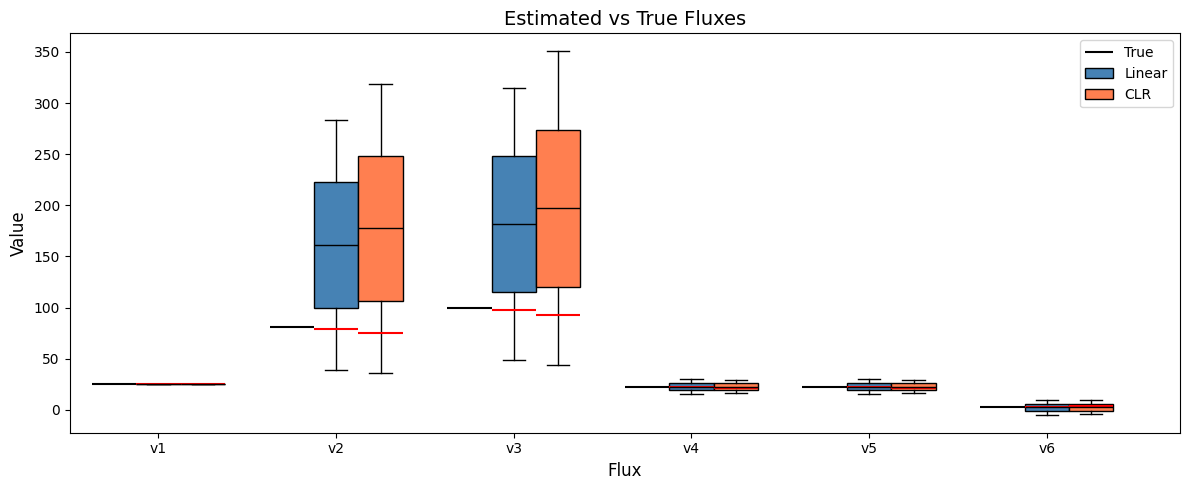

In [141]:
fig, axes = plt.subplots(1, 1, figsize=(12, 5))
flux_labels = ['v1', 'v2', 'v3', 'v4', 'v5', 'v6']
x = np.arange(len(flux_labels))
width = 0.25
axes.hlines(v_true, xmin=x-width*1.5, xmax=x-width*0.5, label='True', color='black')
axes.boxplot(cis, positions=x, widths=width, label='Linear', patch_artist=True, boxprops=dict(facecolor='steelblue', color='black'), medianprops=dict(color='black'))
axes.boxplot(cis_clr, positions=x+width, widths=width, label="CLR",  patch_artist=True, boxprops=dict(facecolor='coral', color='black'), medianprops=dict(color='black'))

axes.hlines(v_est, xmin=x-width*0.5, xmax=x+width*0.5, color='red')
axes.hlines(v_clr, xmin=x+width*0.5, xmax=x+width*1.5, color='red')

axes.set_xlabel('Flux', fontsize=12)
axes.set_ylabel('Value', fontsize=12)
axes.set_title('Estimated vs True Fluxes', fontsize=14)
axes.set_xticks(x)
axes.set_xticklabels(flux_labels)
axes.legend(fontsize=10)

plt.tight_layout()
plt.show()
